# Deep Behavior Analysis: Understanding the Current 2,700 Runs

This notebook explains the deeper analysis requested by Professor Ahmed.

The goal is not only to ask whether neutral prompts perform better, but **why** they perform better.

Main question:

> Does the tone effect remain after controlling for output length, code-only response rate, parsing/extraction failures, and runtime?

If the tone effect becomes much smaller after adding these controls, then the result is better interpreted as:

> Prompt tone changes output behavior, and that behavior affects downstream coding performance.

## 1. Setup

We load the same three result files used in the previous report:

- `gemma2-9b_final.jsonl`
- `llama3.1-8b_final.jsonl`
- `qwen2.5-7b_final.jsonl`

We also load:

- `problems.csv`
- `prompt_matrix_prompt_template.08.csv`

The result `task_id` has the format `problemID_templateID`, for example `1_7`.

In [1]:
from __future__ import annotations

import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
PROBLEMS_PATH = ROOT / "problems.csv"
PROMPT_MATRIX_PATH = ROOT / "prompt_matrix_prompt_template.08.csv"
RESULTS_DIR = ROOT / "results_codeonly"
OUTPUT_DIR = ROOT / "analysis_outputs_codeonly" / "deep_behavior_notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", ROOT)
print("Output directory:", OUTPUT_DIR)

Working directory: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset
Output directory: /Users/macos/LearningSpace/ue-courses/Thesis/01PilotPhrase/pivot_problem_dataset/analysis_outputs_codeonly/deep_behavior_notebook


## 2. Load and Join Data

This cell reads all JSONL result files and joins them with prompt-template metadata.

Important joined columns:

- `model_short`: model name from the result file
- `problem_id`: coding problem id
- `template_id`: prompt template id
- `Tone`, `Role_framing`, `Format`: prompt factors
- `passed`, `tests_passed`, `tests_total`: evaluation result
- `completion_tokens`, `duration_seconds`: behavior/runtime metrics
- `response_text`, `extracted_code`: raw output and extracted code

In [2]:
def read_jsonl(path: Path) -> pd.DataFrame:
    rows = []
    with path.open("r", encoding="utf-8") as handle:
        for line_no, line in enumerate(handle, start=1):
            line = line.strip()
            if not line:
                continue
            row = json.loads(line)
            row["source_file"] = path.name
            rows.append(row)
    return pd.DataFrame(rows)


def parse_result_task_id(value: object) -> tuple[int, int]:
    match = re.fullmatch(r"(\d+)_(\d+)", str(value))
    if not match:
        raise ValueError(f"Unexpected result task_id format: {value!r}")
    return int(match.group(1)), int(match.group(2))


def short_model_name(source_file: str, model_value: object = None) -> str:
    if source_file.endswith("_1_50.jsonl"):
        return source_file.removesuffix("_1_50.jsonl")
    if model_value is not None:
        return str(model_value).replace(":", "-")
    return source_file.removesuffix(".jsonl")


problems = pd.read_csv(PROBLEMS_PATH)
prompt_matrix = pd.read_csv(PROMPT_MATRIX_PATH).rename(columns={"ID": "template_id", "Role framing": "Role_framing"})
result_paths = sorted(RESULTS_DIR.glob("*_1_50.jsonl"))

results = pd.concat([read_jsonl(path) for path in result_paths], ignore_index=True)
parsed_ids = results["task_id"].map(parse_result_task_id)
results["problem_id"] = parsed_ids.map(lambda pair: pair[0])
results["template_id"] = parsed_ids.map(lambda pair: pair[1])
results["model_short"] = [
    short_model_name(src, model)
    for src, model in zip(results["source_file"], results.get("model", pd.Series([None] * len(results))))
]

problem_meta = (
    problems.rename(columns={"task_id": "problem_id"})
    .sort_values(["problem_id", "category_id"])
    .drop_duplicates("problem_id")
    [["problem_id", "prompt", "test_cases", "challenge_test_list"]]
)

df = (
    results.merge(prompt_matrix, on="template_id", how="left", validate="many_to_one")
    .merge(problem_meta, on="problem_id", how="left", validate="many_to_one", suffixes=("", "_problem"))
)

print("Result files:", [p.name for p in result_paths])
print("Rows:", len(df))
print("Models:", df["model_short"].unique())
print("Problems:", df["problem_id"].nunique())
print("Templates:", df["template_id"].nunique())
df.head(3)

Result files: ['gemma2-9b_1_50.jsonl', 'llama3.1-8b_1_50.jsonl', 'qwen2.5-7b_1_50.jsonl']
Rows: 2700
Models: ['gemma2-9b' 'llama3.1-8b' 'qwen2.5-7b']
Problems: 50
Templates: 18


,timestamp,model,task_id,passed,tests_passed,tests_total,errors,duration_seconds,prompt_tokens,completion_tokens,response_text,extracted_code,source_file,problem_id,template_id,model_short,Tone,Pressure,Role_framing,Format,ProblemID,Prompt,FinalPrompt,prompt,test_cases,challenge_test_list
0,2026-05-01T07:51:49.650806,gemma2:9b,1_1,False,0,7,"[Test failed: assert calculate_max_reward(100, 50, 50000) == 9 | Error: list index out of range]",9.304490,213,162,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n count = [0] * (s + 1)\n for i in range(1, n + 1):\n count[i] += 1\n to...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n count = [0] * (s + 1)\n for i in range(1, n + 1):\n count[i] += 1\n total_reward ...",gemma2-9b_1_50.jsonl,1,1,gemma2-9b,neutral,NaN,no role,plaintext,1,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."
1,2026-05-01T07:51:54.109973,gemma2:9b,1_2,False,6,7,[],4.316592,240,112,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n count = 0\n for i in range(1, n - 1):\n for j in range(i + 1, n):\n ...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n count = 0\n for i in range(1, n - 1):\n for j in range(i + 1, n):\n for k...",gemma2-9b_1_50.jsonl,1,2,gemma2-9b,neutral,NaN,no role,json,1,"{\n ""instruction"": ""You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Comp...",NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."
2,2026-05-01T07:51:58.585051,gemma2:9b,1_3,False,6,7,[],4.331424,283,112,"```python\ndef calculate_max_reward(n: int, s: int, r: int) -> int:\n count = 0\n for i in range(1, n - 1):\n for j in range(i + 1, n):\n ...","def calculate_max_reward(n: int, s: int, r: int) -> int:\n count = 0\n for i in range(1, n - 1):\n for j in range(i + 1, n):\n for k...",gemma2-9b_1_50.jsonl,1,3,gemma2-9b,neutral,NaN,no role,xml,1,<prompt>\n<instruction>\nYou are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. ...,NaN,You are an AI assistant dedicated to providing clear and accurate information to support any request.\n\nTasks are provided below. Complete the following Py...,"[""assert calculate_max_reward(100, 100, 50000) == 39"", ""assert calculate_max_reward(50, 50, 20000) == 4""]","[""assert calculate_max_reward(30, 30, 100000) == 6"", ""assert calculate_max_reward(200, 200, 10000) == 32"", ""assert calculate_max_reward(100, 50, 50000) == 9..."


## 3. Create Derived Metrics

We create the variables used in the deep analysis.

Performance metrics:

- `passed_int`: exact pass/fail as 0/1
- `tests_fraction`: fraction of unit tests passed

Behavior metrics:

- `completion_tokens`: output length
- `duration_seconds`: runtime/latency
- `likely_code_only`: whether the response is mostly extracted code
- `extraction_failed`: whether no code was extracted
- `runtime_failure`: syntax/name/import/timeout/empty-code failure proxy
- `extra_text_ratio`: share of response text outside extracted code

Important caveat: `extraction_failed` is a conservative proxy for parsing failure. It catches empty extracted code, but it is not a complete parser-failure taxonomy.

In [3]:
def safe_len(value: object) -> int:
    if isinstance(value, str):
        return len(value)
    if pd.isna(value):
        return 0
    return len(str(value))


def count_lines(value: object) -> int:
    if not isinstance(value, str) or not value.strip():
        return 0
    return len(value.splitlines())


def error_text(errors: object) -> str:
    if isinstance(errors, list):
        return "\n".join(map(str, errors))
    if pd.isna(errors):
        return ""
    return str(errors)


def classify_error(errors: object, extracted_code: object) -> str:
    text = error_text(errors).lower()
    code_value = extracted_code if isinstance(extracted_code, str) else ""
    if not code_value.strip():
        return "missing_or_empty_code"
    if not text.strip():
        return "none"
    if "not defined" in text:
        return "name_not_defined"
    if "syntax" in text or "invalid syntax" in text:
        return "syntax_error"
    if "timeout" in text or "timed out" in text:
        return "timeout"
    if "importerror" in text or "no module named" in text:
        return "import_error"
    if "assert" in text or "test failed" in text:
        return "wrong_answer"
    return "other_runtime"


df["passed_int"] = df["passed"].astype(bool).astype(int)
df["tests_passed"] = pd.to_numeric(df["tests_passed"], errors="coerce")
df["tests_total"] = pd.to_numeric(df["tests_total"], errors="coerce")
df["tests_fraction"] = np.where(df["tests_total"] > 0, df["tests_passed"] / df["tests_total"], np.nan)
df["prompt_tokens"] = pd.to_numeric(df["prompt_tokens"], errors="coerce")
df["completion_tokens"] = pd.to_numeric(df["completion_tokens"], errors="coerce")
df["duration_seconds"] = pd.to_numeric(df["duration_seconds"], errors="coerce")

df["response_chars"] = df["response_text"].map(safe_len)
df["code_chars"] = df["extracted_code"].map(safe_len)
df["response_lines"] = df["response_text"].map(count_lines)
df["code_lines"] = df["extracted_code"].map(count_lines)
df["has_extracted_code"] = (df["code_chars"] > 0).astype(int)
df["extraction_failed"] = (df["has_extracted_code"] == 0).astype(int)
df["extra_text_chars"] = (df["response_chars"] - df["code_chars"]).clip(lower=0)
df["extra_text_ratio"] = np.where(df["response_chars"] > 0, df["extra_text_chars"] / df["response_chars"], np.nan)
df["likely_code_only"] = ((df["has_extracted_code"] == 1) & (df["extra_text_ratio"] < 0.15)).astype(int)
df["error_text"] = df["errors"].map(error_text)
df["error_category"] = [classify_error(e, c) for e, c in zip(df["errors"], df["extracted_code"])]
df["runtime_failure"] = df["error_category"].isin([
    "syntax_error", "name_not_defined", "import_error", "other_runtime", "timeout", "missing_or_empty_code"
]).astype(int)

df["log_completion_tokens"] = np.log1p(df["completion_tokens"])
df["log_duration_seconds"] = np.log1p(df["duration_seconds"])

cols = [
    "model_short", "problem_id", "template_id", "Tone", "Role_framing", "Format",
    "passed_int", "tests_fraction", "completion_tokens", "duration_seconds",
    "likely_code_only", "extraction_failed", "runtime_failure", "extra_text_ratio", "error_category",
]
df[cols].head()

,model_short,problem_id,template_id,Tone,Role_framing,Format,passed_int,tests_fraction,completion_tokens,duration_seconds,likely_code_only,extraction_failed,runtime_failure,extra_text_ratio,error_category
0,gemma2-9b,1,1,neutral,no role,plaintext,0,0.000000,162,9.304490,1,0,0,0.037500,wrong_answer
1,gemma2-9b,1,2,neutral,no role,json,0,0.857143,112,4.316592,1,0,0,0.051546,none
2,gemma2-9b,1,3,neutral,no role,xml,0,0.857143,112,4.331424,1,0,0,0.051546,none
3,gemma2-9b,1,4,neutral,developer role,plaintext,0,0.000000,115,4.376466,1,0,0,0.052632,none
4,gemma2-9b,1,5,neutral,developer role,json,1,1.000000,107,4.150813,1,0,0,0.054945,none


## 4. Descriptive Summary by Tone

This is the first important table.

It shows whether tone changes both performance and output behavior.

Look especially at:

- `completion_tokens`
- `duration_seconds`
- `likely_code_only`
- `passed_int`
- `tests_fraction`

If neutral prompts are shorter, faster, and more code-only, then tone is changing behavior, not only correctness.

In [4]:
tone_summary = (
    df.groupby("Tone")
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        extraction_failure_rate=("extraction_failed", "mean"),
        runtime_failure_rate=("runtime_failure", "mean"),
        extra_text_ratio=("extra_text_ratio", "mean"),
    )
    .reset_index()
)

tone_summary.to_csv(OUTPUT_DIR / "tone_summary.csv", index=False)
tone_summary.style.format({
    "pass_rate": "{:.1%}",
    "tests_fraction": "{:.1%}",
    "avg_completion_tokens": "{:.0f}",
    "avg_duration_seconds": "{:.2f}",
    "code_only_rate": "{:.1%}",
    "extraction_failure_rate": "{:.1%}",
    "runtime_failure_rate": "{:.1%}",
    "extra_text_ratio": "{:.1%}",
})

,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,extraction_failure_rate,runtime_failure_rate,extra_text_ratio
0,aggressive,900,9.2%,14.4%,281,8.71,99.8%,0.0%,39.4%,2.1%
1,neutral,900,12.3%,18.2%,260,8.19,99.1%,0.0%,33.4%,2.3%
2,polite,900,9.2%,14.5%,328,10.11,99.6%,0.0%,46.9%,2.0%


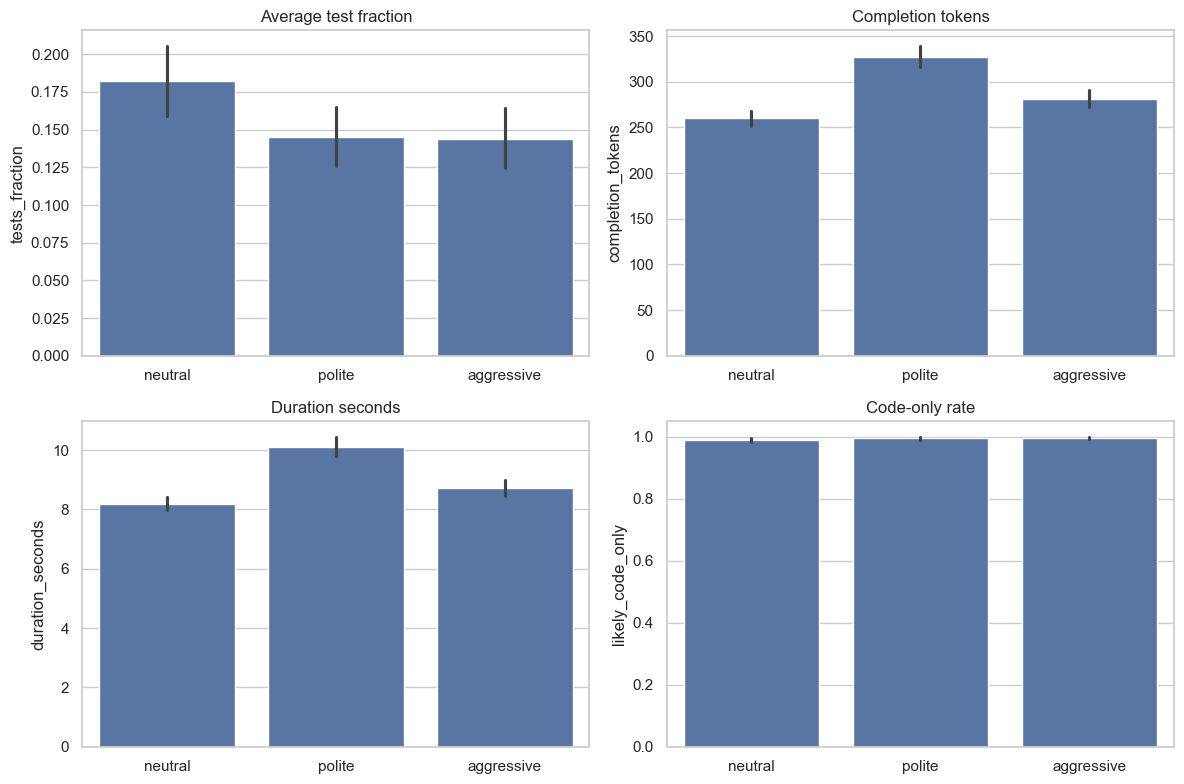

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_specs = [
    ("tests_fraction", "Average test fraction"),
    ("completion_tokens", "Completion tokens"),
    ("duration_seconds", "Duration seconds"),
    ("likely_code_only", "Code-only rate"),
]
for ax, (metric, title) in zip(axes.flat, plot_specs):
    sns.barplot(data=df, x="Tone", y=metric, errorbar=("ci", 95), ax=ax, order=["neutral", "polite", "aggressive"])
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### Interpretation

The descriptive result should show:

- neutral prompts have the best average performance
- neutral prompts are much shorter
- polite/aggressive prompts are slower and more verbose

This motivates the next step: regression with behavior controls.

## 5. Fixed-Effect Regression: Baseline Versus Behavior Controls

This is the core analysis.

We estimate models like:

```text
outcome ~ Tone + Role_framing + Format + model fixed effects + problem fixed effects + behavior controls
```

Why fixed effects?

- `C(model_short)` controls for different baseline model ability.
- `C(problem_id)` controls for different problem difficulty.

The key coefficient is:

```text
C(Tone)[T.neutral]
```

The hidden reference category is aggressive tone. So the neutral coefficient means:

> How much better/worse neutral is compared with aggressive, after controlling for the other variables.

In [6]:
def coef_rows(result, model_name: str, outcome: str) -> pd.DataFrame:
    rows = result.params.rename("coef").to_frame()
    rows["std_err"] = result.bse
    rows["p_value"] = result.pvalues
    rows["model_spec"] = model_name
    rows["outcome"] = outcome
    rows["term"] = rows.index
    return rows.reset_index(drop=True)


def fit_ols(data: pd.DataFrame, outcome: str, controls: list[str], spec_name: str):
    prompt_terms = "C(Tone) + C(Role_framing) + C(Format)"
    fixed_effects = "C(model_short) + C(problem_id)"
    formula = f"{outcome} ~ " + " + ".join([prompt_terms, fixed_effects, *controls])
    model_cols = [outcome, "Tone", "Role_framing", "Format", "model_short", "problem_id", *controls]
    model_data = data[model_cols].dropna()
    result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
    return result, formula


control_sets = {
    "M0_prompt_only": [],
    "M1_length": ["log_completion_tokens"],
    "M2_code_only": ["likely_code_only"],
    "M3_extraction": ["extraction_failed"],
    "M4_runtime": ["log_duration_seconds"],
    "M5_all_behavior_controls": ["log_completion_tokens", "likely_code_only", "extraction_failed", "log_duration_seconds"],
}

ols_rows = []
formulas = []
for outcome in ["passed_int", "tests_fraction"]:
    for spec_name, controls in control_sets.items():
        result, formula = fit_ols(df, outcome, controls, spec_name)
        ols_rows.append(coef_rows(result, spec_name, outcome))
        formulas.append({"outcome": outcome, "model_spec": spec_name, "formula": formula, "nobs": result.nobs, "rsquared": result.rsquared})

ols_results = pd.concat(ols_rows, ignore_index=True)
ols_formulas = pd.DataFrame(formulas)
ols_results.to_csv(OUTPUT_DIR / "behavior_control_ols_models.csv", index=False)
ols_formulas.to_csv(OUTPUT_DIR / "behavior_control_ols_formulas.csv", index=False)

focus_terms = [
    "C(Tone)[T.neutral]", "C(Tone)[T.polite]",
    "log_completion_tokens", "likely_code_only", "extraction_failed", "log_duration_seconds",
]
focus_ols = ols_results[ols_results["term"].isin(focus_terms)].copy()
focus_ols[["outcome", "model_spec", "term", "coef", "std_err", "p_value"]].style.format({
    "coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"
})

,outcome,model_spec,term,coef,std_err,p_value
1,passed_int,M0_prompt_only,C(Tone)[T.neutral],+0.0311,0.0125,0.0131
2,passed_int,M0_prompt_only,C(Tone)[T.polite],-0.0000,0.0121,1.0000
58,passed_int,M1_length,C(Tone)[T.neutral],+0.0292,0.0127,0.0208
59,passed_int,M1_length,C(Tone)[T.polite],+0.0034,0.0123,0.7848
114,passed_int,M1_length,log_completion_tokens,-0.0246,0.0194,0.2061
116,passed_int,M2_code_only,C(Tone)[T.neutral],+0.0272,0.0124,0.0278
117,passed_int,M2_code_only,C(Tone)[T.polite],-0.0013,0.0120,0.9142
172,passed_int,M2_code_only,likely_code_only,-0.5821,0.1126,0.0000
174,passed_int,M3_extraction,C(Tone)[T.neutral],+0.0311,0.0125,0.0131
175,passed_int,M3_extraction,C(Tone)[T.polite],-0.0000,0.0121,1.0000


## 6. Read the Regression Result

Focus on `C(Tone)[T.neutral]`.

Expected pattern from the current run:

- In `M0_prompt_only`, neutral is significantly better.
- After adding output length, the neutral effect becomes small/non-significant.
- After adding code-only compliance, the neutral effect becomes small/non-significant.
- After adding runtime, the neutral effect becomes small/non-significant.
- With all behavior controls, the neutral effect is no longer significant.

This supports the interpretation:

> The neutral-tone advantage is largely explained by output behavior.

Important nuance:

`extraction_failed` alone does not explain the neutral effect. This is because neutral prompts actually had more empty extracted-code cases than polite prompts, mostly from Llama. So extraction failure is important, but it is not the main explanation of neutral's advantage.

In [7]:
neutral_summary = (
    focus_ols[focus_ols["term"].eq("C(Tone)[T.neutral]")]
    .pivot_table(index=["outcome", "model_spec"], values=["coef", "p_value"], aggfunc="first")
    .reset_index()
)
neutral_summary.to_csv(OUTPUT_DIR / "neutral_effect_by_control_model.csv", index=False)
neutral_summary.style.format({"coef": "{:+.4f}", "p_value": "{:.4f}"})

,outcome,model_spec,coef,p_value
0,passed_int,M0_prompt_only,+0.0311,0.0131
1,passed_int,M1_length,+0.0292,0.0208
2,passed_int,M2_code_only,+0.0272,0.0278
3,passed_int,M3_extraction,+0.0311,0.0131
4,passed_int,M4_runtime,+0.0297,0.0187
5,passed_int,M5_all_behavior_controls,+0.0297,0.0179
6,tests_fraction,M0_prompt_only,+0.0379,0.0041
7,tests_fraction,M1_length,+0.0359,0.0071
8,tests_fraction,M2_code_only,+0.0342,0.0090
9,tests_fraction,M3_extraction,+0.0379,0.0041


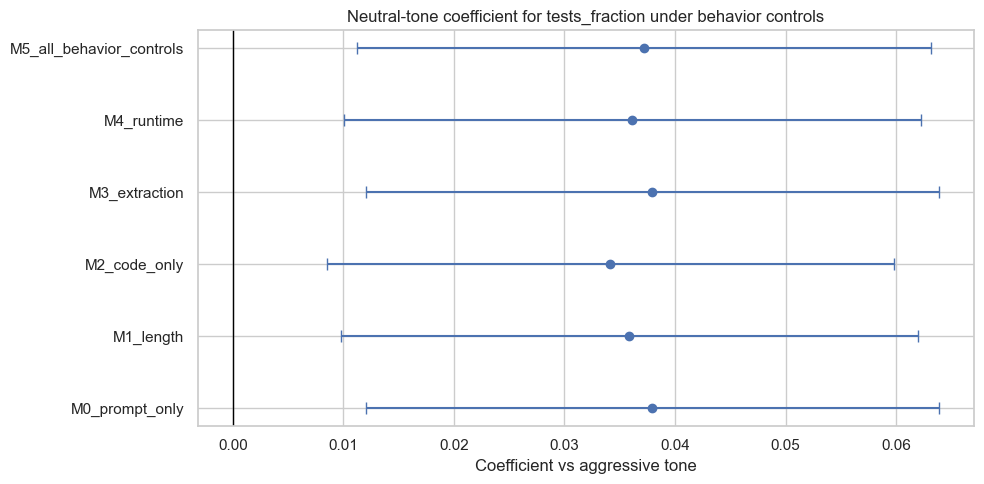

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_data = focus_ols[(focus_ols["term"] == "C(Tone)[T.neutral]") & (focus_ols["outcome"] == "tests_fraction")].copy()
plot_data["ci_low"] = plot_data["coef"] - 1.96 * plot_data["std_err"]
plot_data["ci_high"] = plot_data["coef"] + 1.96 * plot_data["std_err"]

ax.errorbar(
    x=plot_data["coef"],
    y=plot_data["model_spec"],
    xerr=[plot_data["coef"] - plot_data["ci_low"], plot_data["ci_high"] - plot_data["coef"]],
    fmt="o",
    capsize=4,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Neutral-tone coefficient for tests_fraction under behavior controls")
ax.set_xlabel("Coefficient vs aggressive tone")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 7. Logistic Robustness Check

Because `passed_int` is binary, OLS is easy to interpret but not the only option.

This cell runs a binomial GLM/logit model for pass/fail.

Question:

> Does the same qualitative pattern appear when using a binary-outcome model?

In the current data, yes: the baseline neutral effect is significant, but after behavior controls it is no longer significant.

In [9]:
def fit_glm_binomial(data: pd.DataFrame, controls: list[str], spec_name: str):
    prompt_terms = "C(Tone) + C(Role_framing) + C(Format)"
    fixed_effects = "C(model_short) + C(problem_id)"
    formula = "passed_int ~ " + " + ".join([prompt_terms, fixed_effects, *controls])
    model_cols = ["passed_int", "Tone", "Role_framing", "Format", "model_short", "problem_id", *controls]
    model_data = data[model_cols].dropna()
    result = smf.glm(formula=formula, data=model_data, family=sm.families.Binomial()).fit(cov_type="HC3")
    return result, formula


glm_rows = []
glm_formulas = []
glm_failures = []
for spec_name, controls in control_sets.items():
    try:
        result, formula = fit_glm_binomial(df, controls, spec_name)
    except Exception as exc:
        prompt_terms = "C(Tone) + C(Role_framing) + C(Format)"
        fixed_effects = "C(model_short) + C(problem_id)"
        formula = "passed_int ~ " + " + ".join([prompt_terms, fixed_effects, *controls])
        glm_failures.append({
            "model_spec": spec_name,
            "formula": formula,
            "error_type": type(exc).__name__,
            "error": str(exc),
        })
        continue
    glm_rows.append(coef_rows(result, spec_name, "passed_int_glm_binomial_logit"))
    glm_formulas.append({"outcome": "passed_int", "model_spec": spec_name, "formula": formula, "nobs": result.nobs, "aic": result.aic})

if glm_rows:
    glm_results = pd.concat(glm_rows, ignore_index=True)
else:
    glm_results = pd.DataFrame(columns=["coef", "std_err", "p_value", "model_spec", "outcome", "term"])

glm_results.to_csv(OUTPUT_DIR / "behavior_control_glm_logit_models.csv", index=False)
pd.DataFrame(glm_formulas).to_csv(OUTPUT_DIR / "behavior_control_glm_formulas.csv", index=False)
pd.DataFrame(glm_failures).to_csv(OUTPUT_DIR / "behavior_control_glm_failures.csv", index=False)

if glm_failures:
    print("Some logistic robustness models could not be estimated, usually because code-only mode makes a control nearly constant or the design matrix singular.")
    display(pd.DataFrame(glm_failures))

focus_glm = glm_results[glm_results["term"].isin(focus_terms)].copy()
if focus_glm.empty:
    print("No logistic robustness coefficients were estimable. Use the OLS robustness models above for this code-only analysis.")
else:
    display(focus_glm[["model_spec", "term", "coef", "std_err", "p_value"]].style.format({
        "coef": "{:+.4f}", "std_err": "{:.4f}", "p_value": "{:.4f}"
    }))


Some logistic robustness models could not be estimated, usually because code-only mode makes a control nearly constant or the design matrix singular.


,model_spec,formula,error_type,error
0,M3_extraction,passed_int ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id) + extraction_failed,LinAlgError,Singular matrix
1,M5_all_behavior_controls,passed_int ~ C(Tone) + C(Role_framing) + C(Format) + C(model_short) + C(problem_id) + log_completion_tokens + likely_code_only + extraction_failed + log_dur...,LinAlgError,Singular matrix


,model_spec,term,coef,std_err,p_value
1,M0_prompt_only,C(Tone)[T.neutral],+0.4696,0.1815,0.0097
2,M0_prompt_only,C(Tone)[T.polite],+0.0000,0.1904,1.0000
58,M1_length,C(Tone)[T.neutral],+0.4522,0.1820,0.0130
59,M1_length,C(Tone)[T.polite],+0.0365,0.1924,0.8496
114,M1_length,log_completion_tokens,-0.2783,0.2298,0.2259
116,M2_code_only,C(Tone)[T.neutral],+0.4238,0.1836,0.0210
117,M2_code_only,C(Tone)[T.polite],-0.0145,0.1927,0.9401
172,M2_code_only,likely_code_only,-3.9775,0.8659,0.0000
174,M4_runtime,C(Tone)[T.neutral],+0.4562,0.1820,0.0122
175,M4_runtime,C(Tone)[T.polite],+0.0378,0.1932,0.8451


## 8. Behavior Metric Correlations

This table checks how behavior variables relate to each other.

Important result from the current data:

- `completion_tokens` and `duration_seconds` are almost perfectly correlated.

That means when both are included together, their individual coefficients are hard to interpret. The all-controls model is useful as a robustness check, but not as a clean separation of length versus runtime.

In [10]:
corr_cols = [
    "passed_int", "tests_fraction", "completion_tokens", "duration_seconds",
    "likely_code_only", "extraction_failed", "runtime_failure", "extra_text_ratio",
]
correlations = df[corr_cols].corr(method="pearson")
correlations.to_csv(OUTPUT_DIR / "behavior_metric_correlations.csv")
correlations.style.format("{:.3f}").background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,passed_int,tests_fraction,completion_tokens,duration_seconds,likely_code_only,extraction_failed,runtime_failure,extra_text_ratio
passed_int,1.000,0.858,-0.059,-0.059,-0.163,nan,-0.276,0.100
tests_fraction,0.858,1.000,-0.074,-0.070,-0.141,nan,-0.379,0.108
completion_tokens,-0.059,-0.074,1.000,0.995,0.122,nan,0.130,-0.632
duration_seconds,-0.059,-0.070,0.995,1.000,0.124,nan,0.127,-0.618
likely_code_only,-0.163,-0.141,0.122,0.124,1.000,nan,0.059,-0.511
extraction_failed,nan,nan,nan,nan,nan,nan,nan,nan
runtime_failure,-0.276,-0.379,0.130,0.127,0.059,nan,1.000,-0.139
extra_text_ratio,0.100,0.108,-0.632,-0.618,-0.511,nan,-0.139,1.000


## 9. Model-Specific Analysis

Now we check whether the tone effect is consistent across models.

This matters because a publishable paper should avoid overclaiming.

Question:

> Is neutral tone best for every model, or mainly best overall?

In [11]:
model_tone = (
    df.groupby(["model_short", "Tone"])
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        extraction_failure_rate=("extraction_failed", "mean"),
        runtime_failure_rate=("runtime_failure", "mean"),
    )
    .reset_index()
    .sort_values(["model_short", "tests_fraction"], ascending=[True, False])
)
model_tone.to_csv(OUTPUT_DIR / "model_by_tone_behavior_summary.csv", index=False)
model_tone.style.format({
    "pass_rate": "{:.1%}",
    "tests_fraction": "{:.1%}",
    "avg_completion_tokens": "{:.0f}",
    "avg_duration_seconds": "{:.2f}",
    "code_only_rate": "{:.1%}",
    "extraction_failure_rate": "{:.1%}",
    "runtime_failure_rate": "{:.1%}",
})

,model_short,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,extraction_failure_rate,runtime_failure_rate
1,gemma2-9b,neutral,300,11.7%,20.7%,168,6.05,97.3%,0.0%,23.7%
2,gemma2-9b,polite,300,10.7%,18.5%,187,6.64,98.7%,0.0%,34.0%
0,gemma2-9b,aggressive,300,11.0%,17.4%,183,6.50,99.3%,0.0%,37.3%
4,llama3.1-8b,neutral,300,8.7%,14.2%,335,10.08,100.0%,0.0%,40.3%
5,llama3.1-8b,polite,300,6.3%,10.7%,452,13.40,100.0%,0.0%,56.3%
3,llama3.1-8b,aggressive,300,3.7%,7.9%,379,11.23,100.0%,0.0%,46.0%
7,qwen2.5-7b,neutral,300,16.7%,19.7%,278,8.45,100.0%,0.0%,36.3%
6,qwen2.5-7b,aggressive,300,13.0%,17.9%,281,8.42,100.0%,0.0%,35.0%
8,qwen2.5-7b,polite,300,10.7%,14.4%,344,10.29,100.0%,0.0%,50.3%


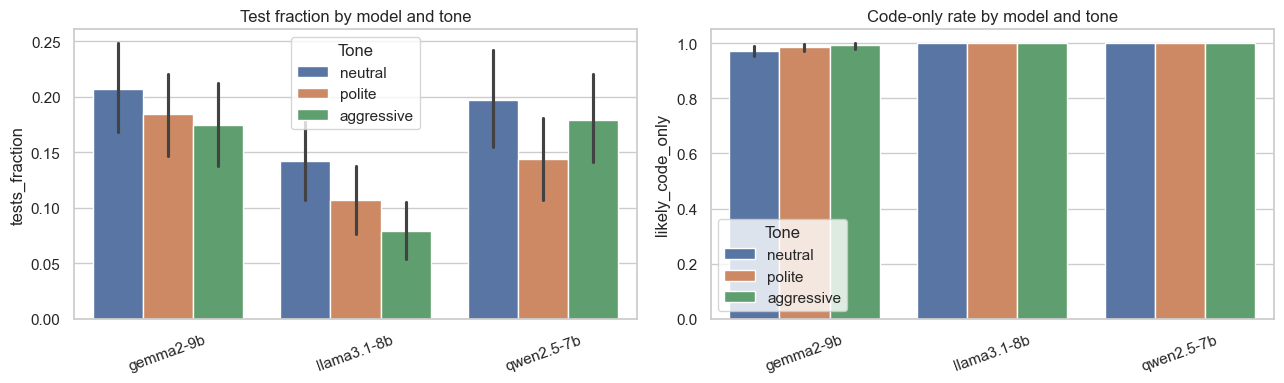

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="model_short", y="tests_fraction", hue="Tone", errorbar=("ci", 95), ax=axes[0], hue_order=["neutral", "polite", "aggressive"])
axes[0].set_title("Test fraction by model and tone")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=df, x="model_short", y="likely_code_only", hue="Tone", errorbar=("ci", 95), ax=axes[1], hue_order=["neutral", "polite", "aggressive"])
axes[1].set_title("Code-only rate by model and tone")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Interpretation

In the current result:

- neutral is strongest for Gemma and Qwen
- Llama is the caveat: polite is slightly higher by `tests_fraction`
- neutral has high extraction failure for Llama compared with the other models

So the safe wording is:

> Neutral tone produced the strongest overall result, but the effect is mediated by output behavior and varies across model families.

## 10. Difficulty Analysis

A prompt technique may help on medium/easy tasks but not on tasks that are too hard for all models.

Here we split problems into three difficulty bands based on average `tests_fraction` across all runs.

In [13]:
problem_difficulty = (
    df.groupby("problem_id")
    .agg(problem_mean_tests_fraction=("tests_fraction", "mean"), problem_pass_rate=("passed_int", "mean"))
    .reset_index()
)
problem_difficulty["difficulty_band"] = pd.qcut(
    problem_difficulty["problem_mean_tests_fraction"],
    q=3,
    labels=["hard", "medium", "easy"],
    duplicates="drop",
)

df = df.drop(columns=["difficulty_band"], errors="ignore").merge(
    problem_difficulty[["problem_id", "difficulty_band"]], on="problem_id", how="left"
)

difficulty_tone = (
    df.groupby(["difficulty_band", "Tone"], observed=False)
    .agg(
        runs=("task_id", "size"),
        pass_rate=("passed_int", "mean"),
        tests_fraction=("tests_fraction", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_duration_seconds=("duration_seconds", "mean"),
        code_only_rate=("likely_code_only", "mean"),
        extraction_failure_rate=("extraction_failed", "mean"),
        runtime_failure_rate=("runtime_failure", "mean"),
    )
    .reset_index()
)
difficulty_tone.to_csv(OUTPUT_DIR / "difficulty_by_tone_behavior_summary.csv", index=False)
difficulty_tone.style.format({
    "pass_rate": "{:.1%}",
    "tests_fraction": "{:.1%}",
    "avg_completion_tokens": "{:.0f}",
    "avg_duration_seconds": "{:.2f}",
    "code_only_rate": "{:.1%}",
    "extraction_failure_rate": "{:.1%}",
    "runtime_failure_rate": "{:.1%}",
})

,difficulty_band,Tone,runs,pass_rate,tests_fraction,avg_completion_tokens,avg_duration_seconds,code_only_rate,extraction_failure_rate,runtime_failure_rate
0,hard,aggressive,306,0.0%,0.4%,278,8.64,100.0%,0.0%,63.4%
1,hard,neutral,306,0.3%,0.7%,256,8.06,100.0%,0.0%,61.4%
2,hard,polite,306,0.0%,0.5%,330,10.18,100.0%,0.0%,68.6%
3,medium,aggressive,288,3.1%,8.1%,261,8.16,100.0%,0.0%,30.9%
4,medium,neutral,288,3.8%,9.6%,246,7.80,99.3%,0.0%,25.3%
5,medium,polite,288,3.5%,8.3%,304,9.42,99.7%,0.0%,41.0%
6,easy,aggressive,306,24.2%,34.4%,302,9.32,99.3%,0.0%,23.5%
7,easy,neutral,306,32.4%,43.8%,278,8.69,98.0%,0.0%,13.1%
8,easy,polite,306,23.9%,34.5%,348,10.68,99.0%,0.0%,30.7%


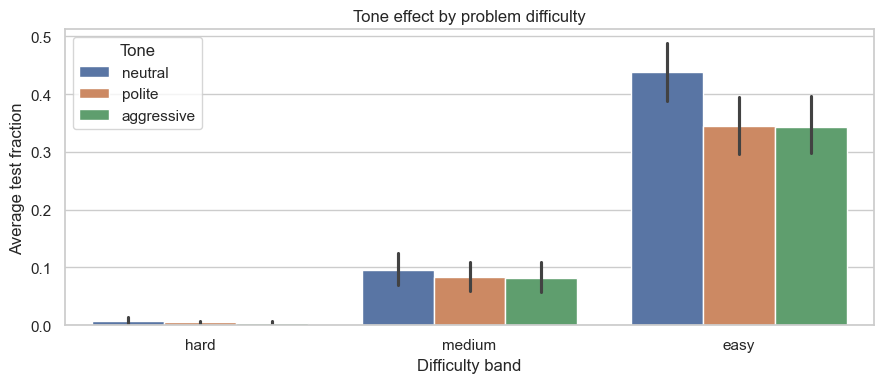

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=df, x="difficulty_band", y="tests_fraction", hue="Tone", errorbar=("ci", 95), ax=ax, hue_order=["neutral", "polite", "aggressive"])
ax.set_title("Tone effect by problem difficulty")
ax.set_xlabel("Difficulty band")
ax.set_ylabel("Average test fraction")
plt.tight_layout()
plt.show()

### Interpretation

The current data suggests:

- hard problems are near zero for all tones
- neutral helps most on medium and easy problems
- prompt tone cannot rescue problems that are beyond the current model/problem setup

## 11. Error Mode Analysis

This checks what kind of failures happen under each tone.

The most useful categories are:

- `wrong_answer`
- `name_not_defined`
- `missing_or_empty_code`
- `timeout`
- `syntax_error`

In [15]:
error_summary = (
    df.groupby(["Tone", "error_category"])
    .size()
    .rename("runs")
    .reset_index()
)
error_summary["rate"] = error_summary["runs"] / error_summary.groupby("Tone")["runs"].transform("sum")
error_summary = error_summary.sort_values(["Tone", "runs"], ascending=[True, False])
error_summary.to_csv(OUTPUT_DIR / "tone_error_category_summary.csv", index=False)
error_summary.style.format({"rate": "{:.1%}"})

,Tone,error_category,runs,rate
1,aggressive,none,498,55.3%
0,aggressive,name_not_defined,330,36.7%
4,aggressive,wrong_answer,47,5.2%
3,aggressive,timeout,19,2.1%
2,aggressive,other_runtime,6,0.7%
6,neutral,none,548,60.9%
5,neutral,name_not_defined,285,31.7%
9,neutral,wrong_answer,51,5.7%
8,neutral,timeout,14,1.6%
7,neutral,other_runtime,2,0.2%


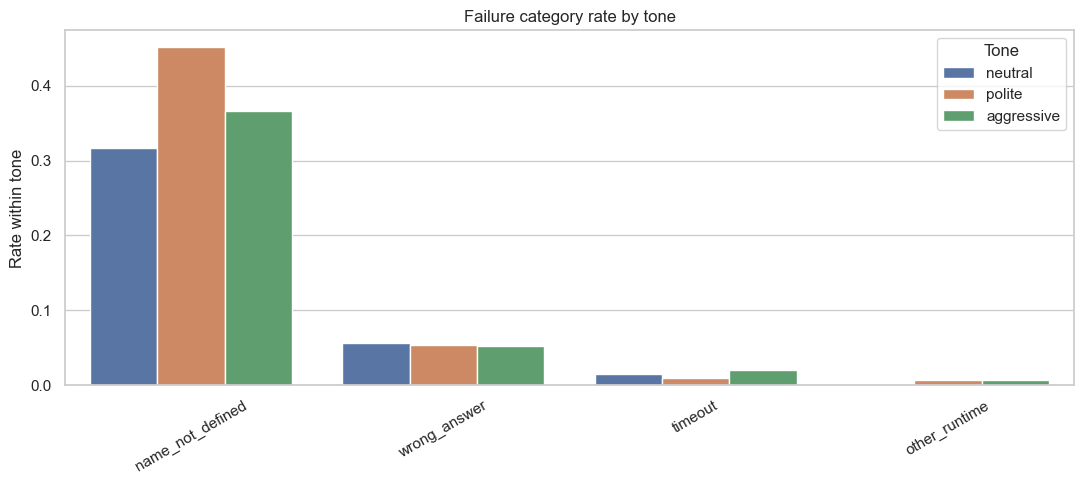

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))
plot_errors = error_summary[error_summary["error_category"].ne("none")].copy()
sns.barplot(data=plot_errors, x="error_category", y="rate", hue="Tone", ax=ax, hue_order=["neutral", "polite", "aggressive"])
ax.set_title("Failure category rate by tone")
ax.set_xlabel("")
ax.set_ylabel("Rate within tone")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()